# Etapa 3: otimização e IA responsável

A Etapa 2 escolheu a regressão logística, com acerto geral (F1 macro) de 0,5794 na validação, à frente do LightGBM sem
ajustes (0,5762). Ela deixou dois pontos abertos: os dias Alto avisados ficaram abaixo de 60 de cada 100, e o modelo perdia
para a persistência (a régua "o risco de hoje é o de ontem") nos municípios pequenos.

Esta etapa otimiza o **LightGBM**, que o enunciado sugere para a otimização e que tem muito mais ajustes para testar do que a
regressão logística. O critério continua o mesmo: se, depois de otimizado, ele passar da regressão logística na validação,
vira o modelo final. Esta etapa:

1. ajusta o modelo com o **Optuna**, ferramenta que testa combinações de ajustes (os hiperparâmetros) e usa o
   resultado de cada tentativa para escolher a próxima;
2. testa um **corte do Alto** (a probabilidade a partir da qual o dia vira Alto) **para cada faixa de tamanho** de município;
3. explica as decisões com o **SHAP**, método que mostra quanto cada coluna pesou em cada previsão;
4. procura **viés** (o modelo errar mais para um grupo) por região, bioma e distância até a estação meteorológica;
5. gera um **boletim em texto** por município, com regra fixa;
6. responde à hipótese do projeto.

As métricas são as da seção 2 do `02_modelagem.ipynb`. Como na Etapa 2, **os ajustes e os cortes são escolhidos na
validação** (outubro de 2024); o teste (novembro de 2024 a fevereiro de 2025) mede o resultado.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', message='IProgress not found')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import optuna
import shap
from sklearn.metrics import f1_score

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'consolidar_base.py').exists())
sys.path.insert(0, str(RAIZ / 'src'))
import preparar_modelagem as pm

RESULTADOS = RAIZ / 'resultados' / 'etapa3'
RESULTADOS.mkdir(parents=True, exist_ok=True)
AZUL, CINZA, LARANJA, VERMELHO = '#2f6fdb', '#9aa5b1', '#e8a33d', '#c0392b'
SEMENTE = 12345
optuna.logging.set_verbosity(optuna.logging.WARNING)

base = pm.carregar_base()
treino, validacao, teste = pm.dividir_por_tempo(base)
amostra = treino.sample(400_000, random_state=SEMENTE)
X_am, y_am = amostra[pm.FEATURES], amostra['nivel_risco'].astype(str)
X_va, y_va = validacao[pm.FEATURES], validacao['nivel_risco'].astype(str)
X_te, y_te = teste[pm.FEATURES], teste['nivel_risco'].astype(str)
persistencia_te = pm.persistencia(teste).values

COMUM = dict(class_weight='balanced', random_state=SEMENTE, verbose=-1, deterministic=True, force_row_wise=True)

print(f'treino {len(treino):,} | amostra {len(amostra):,} | validação {len(validacao):,} | teste {len(teste):,}'.replace(',', ' '))

treino 1 355 812 | amostra 400 000 | validação 172 316 | teste 578 283


## 1. Otimização com o Optuna

**O que é ajustado:** o número de árvores, a velocidade de aprendizado, o tamanho das árvores, o mínimo de linhas
em cada folha (a ponta da árvore, onde sai a resposta), a fração de linhas e de colunas usada em cada árvore e a
força da regularização (um freio que evita decorar o treino).

**Critério, fixado antes de começar:** o maior acerto geral (F1 macro) na validação, com as notas de corte escolhidas
dentro de cada tentativa. É o mesmo critério da Etapa 2. São **30 tentativas**, cada uma treinada na mesma amostra
de 400 mil linhas.

In [2]:
GRADE_ALTO = np.round(np.arange(0.20, 0.76, 0.05), 2)
GRADE_MEDIO = (0.40, 0.45, 0.50, 0.55, 0.60)

def melhores_cortes(y, prob):
    # Grade mais curta que a da Etapa 2, para caber em cada tentativa do Optuna.
    return pm.escolher_cortes(y, prob, GRADE_ALTO, GRADE_MEDIO)

def tentativa(trial):
    ajustes = dict(n_estimators=trial.suggest_int('n_estimators', 150, 700, step=50),
                   learning_rate=trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
                   num_leaves=trial.suggest_int('num_leaves', 15, 127),
                   min_child_samples=trial.suggest_int('min_child_samples', 20, 400),
                   subsample=trial.suggest_float('subsample', 0.6, 1.0),
                   colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
                   reg_lambda=trial.suggest_float('reg_lambda', 1e-2, 50, log=True))
    modelo = lgb.LGBMClassifier(**ajustes, subsample_freq=1, **COMUM).fit(X_am, y_am)
    return melhores_cortes(y_va, pm.probabilidades(modelo, X_va))[2]

inicio = time.time()
estudo = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEMENTE))
estudo.optimize(tentativa, n_trials=30)
print(f'{time.time() - inicio:.0f} s | melhor F1 macro na validação: {estudo.best_value:.4f}'.replace('.', ','))
(RESULTADOS / 'melhores_ajustes.json').write_text(json.dumps(estudo.best_params, indent=1))
pd.Series(estudo.best_params).round(4).to_frame('valor')

675 s | melhor F1 macro na validação: 0,5874


,valor
n_estimators,700.0000
learning_rate,0.0110
num_leaves,49.0000
min_child_samples,67.0000
subsample,0.8381
colsample_bytree,0.5886
reg_lambda,0.6250


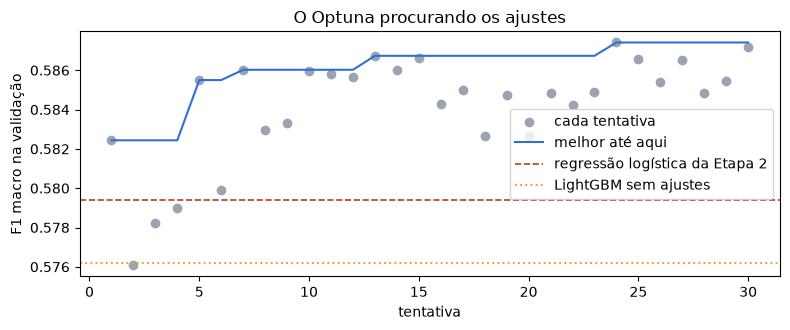

In [3]:
f1_etapa2 = pd.read_csv(RAIZ / 'resultados' / 'etapa2' / 'cortes_validacao.csv', index_col=0)['f1_macro_validacao']
historico = pd.Series([t.value for t in estudo.trials], index=range(1, len(estudo.trials) + 1))
fig, eixo = plt.subplots(figsize=(8, 3.4))
eixo.scatter(historico.index, historico.values, color=CINZA, label='cada tentativa')
eixo.plot(historico.index, historico.cummax(), color=AZUL, label='melhor até aqui')
eixo.axhline(f1_etapa2['Regressão logística'], color=VERMELHO, linestyle='--', linewidth=1.2, label='regressão logística da Etapa 2')
eixo.axhline(f1_etapa2['LightGBM'], color=LARANJA, linestyle=':', linewidth=1.4, label='LightGBM sem ajustes')
eixo.set_xlabel('tentativa')
eixo.set_ylabel('F1 macro na validação')
eixo.set_title('O Optuna procurando os ajustes')
eixo.legend()
plt.tight_layout()
plt.show()

O Optuna subiu o acerto geral do LightGBM na validação de 0,5762 para 0,5874, acima dos 0,5794 da regressão logística. Pelo
critério da Etapa 2, **o LightGBM otimizado passa a ser o modelo final**. Os ajustes vencedores usam mais árvores (700 contra
400), cada uma menor (49 folhas contra 63) e aprendendo mais devagar (taxa de 0,011 contra 0,05). O número de árvores ficou
no máximo testado, então mais árvores poderiam render um pouco mais. O ganho é modesto, como costuma ser: o que mais limita
o resultado é a informação disponível na véspera, e não os ajustes do modelo.

## 2. Um corte do Alto para cada tamanho de município

A Etapa 2 usou um corte único para o país. Mas os municípios pequenos quase não têm dias Alto, e o modelo dá a eles
probabilidades mais baixas: um corte único quase nunca os avisa. A ideia é simples: dividir os municípios em cinco
faixas de área (com os limites calculados no treino) e escolher, **na validação**, o corte do Alto de cada faixa,
pelo maior F1 do Alto.

Esta variante é comparada com quatro referências: a persistência, a regressão logística da Etapa 2, o LightGBM sem ajustes
e o modelo otimizado com corte único.

In [4]:
AJUSTES_ETAPA2 = dict(n_estimators=400, learning_rate=0.05, num_leaves=63)
modelo_etapa2 = lgb.LGBMClassifier(**AJUSTES_ETAPA2, **COMUM).fit(X_am, y_am)
modelo = lgb.LGBMClassifier(**estudo.best_params, subsample_freq=1, **COMUM).fit(X_am, y_am)

prob_va, prob_te = pm.probabilidades(modelo, X_va), pm.probabilidades(modelo, X_te)
prob_va_e2, prob_te_e2 = pm.probabilidades(modelo_etapa2, X_va), pm.probabilidades(modelo_etapa2, X_te)
corte_alto, corte_medio, _ = melhores_cortes(y_va, prob_va)
corte_alto_e2, corte_medio_e2, _ = melhores_cortes(y_va, prob_va_e2)

municipios_treino = treino.drop_duplicates('id_municipio')['area_km2']
LIMITES_AREA = np.quantile(municipios_treino, [.2, .4, .6, .8])
NOMES_FAIXA = ['1 (menores)', '2', '3', '4', '5 (maiores)']
faixa_va, faixa_te = np.digitize(validacao['area_km2'], LIMITES_AREA), np.digitize(teste['area_km2'], LIMITES_AREA)

y_va_np, y_te_np = y_va.values, y_te.values
cortes_faixa = {}
for faixa in range(5):
    dentro = faixa_va == faixa
    notas = {c: f1_score(y_va_np[dentro] == 'Alto', pm.decidir(prob_va[dentro], c, corte_medio) == 'Alto')
             for c in np.round(np.arange(0.05, 0.91, 0.05), 2)}
    cortes_faixa[faixa] = max(notas, key=notas.get)

def decidir_por_faixa(prob, faixas):
    cortes = np.array([cortes_faixa[f] for f in faixas])
    return np.where(prob[:, 2] >= cortes, 'Alto', np.where(prob[:, 1] >= corte_medio, 'Médio', 'Baixo'))

prev_unico_te = pm.decidir(prob_te, corte_alto, corte_medio)
prev_faixa_te = decidir_por_faixa(prob_te, faixa_te)
prev_faixa_va = decidir_por_faixa(prob_va, faixa_va)

print(f'Corte único: {corte_alto:.2f} | corte do Médio: {corte_medio:.2f}'.replace('.', ','))
print('Corte por faixa:', ' | '.join(f'{NOMES_FAIXA[f]}: {c:.2f}'.replace('.', ',') for f, c in cortes_faixa.items()))

# Guarda o modelo final e as regras de decisão, para reuso sem treinar de novo.
modelo.booster_.save_model(str(RESULTADOS / 'modelo_final.txt'))
(RESULTADOS / 'cortes_finais.json').write_text(json.dumps(
    {'limites_area_km2': [round(float(l), 2) for l in LIMITES_AREA], 'corte_alto_por_faixa': [float(cortes_faixa[f]) for f in range(5)],
     'corte_medio': float(corte_medio)}, indent=1))
na_validacao = pd.DataFrame({'corte único': pm.metricas(y_va, pm.decidir(prob_va, corte_alto, corte_medio)),
                             'corte por faixa': pm.metricas(y_va, prev_faixa_va)}).T[['f1_macro', 'precisao_alto', 'recall_alto', 'f1_alto']].round(4)
na_validacao.to_csv(RESULTADOS / 'cortes_na_validacao.csv')
na_validacao

Corte único: 0,50 | corte do Médio: 0,50
Corte por faixa: 1 (menores): 0,35 | 2: 0,45 | 3: 0,40 | 4: 0,45 | 5 (maiores): 0,55


,f1_macro,precisao_alto,recall_alto,f1_alto
corte único,0.5874,0.6290,0.6460,0.6374
corte por faixa,0.5821,0.5997,0.6561,0.6266


In [5]:
opcoes = {'Persistência': (persistencia_te, None),
          'LightGBM sem ajustes': (pm.decidir(prob_te_e2, corte_alto_e2, corte_medio_e2), prob_te_e2),
          'Otimizado, corte único': (prev_unico_te, prob_te),
          'Otimizado, corte por faixa': (prev_faixa_te, prob_te)}
comparacao = pd.DataFrame({nome: pm.metricas(y_te, previsto, prob) for nome, (previsto, prob) in opcoes.items()}).T[
    ['acuracia', 'f1_macro', 'precisao_alto', 'recall_alto', 'f1_alto', 'f1_medio', 'auc_roc']].round(4)
custos = [pm.custo_total(y_te_np, previsto) for previsto, _ in opcoes.values()]
comparacao['custo (R$ milhões)'] = [round(total / 1e6, 1) for total, _, _ in custos]
comparacao['avisos Alto'] = [avisos for _, avisos, _ in custos]
comparacao['dias Alto sem aviso'] = [perdidos for _, _, perdidos in custos]
logistica = pd.read_csv(RAIZ / 'resultados' / 'etapa2' / 'metricas_teste.csv', index_col=0).loc['Regressão logística'].to_dict()
custo_logistica = pd.read_csv(RAIZ / 'resultados' / 'etapa2' / 'custo_em_reais.csv', index_col=0).loc['Regressão logística']
logistica.update({'custo (R$ milhões)': custo_logistica['custo total (R$ milhões)'], 'avisos Alto': custo_logistica['avisos Alto'],
                  'dias Alto sem aviso': custo_logistica['dias Alto sem aviso']})
comparacao = pd.concat([comparacao.iloc[:1], pd.DataFrame([logistica], index=['Regressão logística da Etapa 2'])[comparacao.columns], comparacao.iloc[1:]])
comparacao.to_csv(RESULTADOS / 'comparacao_teste.csv')
comparacao

,acuracia,f1_macro,precisao_alto,recall_alto,f1_alto,f1_medio,auc_roc,custo (R$ milhões),avisos Alto,dias Alto sem aviso
Persistência,0.8423,0.5490,0.4921,0.4982,0.4951,0.2295,NaN,434.8,30961.0,15347.0
Regressão logística da Etapa 2,0.8174,0.5649,0.5870,0.4988,0.5393,0.2519,0.8550,429.2,25985.0,15329.0
LightGBM sem ajustes,0.8196,0.5603,0.5323,0.4778,0.5036,0.2702,0.8526,447.5,27453.0,15970.0
"Otimizado, corte único",0.7690,0.5665,0.5792,0.4995,0.5364,0.2903,0.8619,429.0,26378.0,15306.0
"Otimizado, corte por faixa",0.7693,0.5677,0.5677,0.5179,0.5416,0.2881,0.8619,415.8,27898.0,14745.0


In [6]:
sensibilidade = pm.sensibilidade_economia(y_te_np, prev_faixa_te, persistencia_te)
sensibilidade.to_csv(RESULTADOS / 'sensibilidade_economia.csv')
print('Economia do modelo final contra a persistência, em R$ milhões, no período de teste:')
sensibilidade

Economia do modelo final contra a persistência, em R$ milhões, no período de teste:


,equipe R$ 500,equipe R$ 1.032,equipe R$ 2.000
área a mais queimada sem equipe,,,
1 ha,4.7,6.3,9.3
2 ha,7.9,9.5,12.4
5 ha,17.3,19.0,21.9
10 ha,33.1,34.8,37.7
20 ha,64.7,66.4,69.3


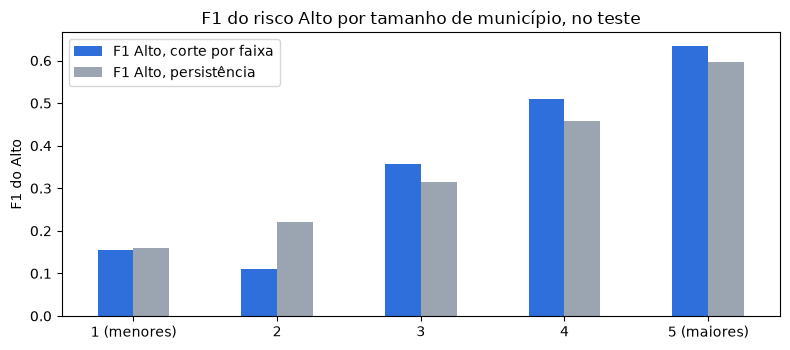

,corte do Alto,% dias Alto,"F1 Alto, corte por faixa","F1 Alto, corte único","F1 Alto, persistência"
faixa de área,,,,,
1 (menores),0.35,0.76,0.1546,0.0281,0.1590
2,0.45,1.57,0.1114,0.0621,0.2212
3,0.40,3.03,0.3573,0.2533,0.3155
4,0.45,6.60,0.5090,0.4817,0.4583
5 (maiores),0.55,14.48,0.6346,0.6327,0.5966


In [7]:
por_tamanho = []
for faixa in range(5):
    dentro = faixa_te == faixa
    modelo_f = pm.metricas(y_te_np[dentro], prev_faixa_te[dentro])
    unico_f = pm.metricas(y_te_np[dentro], prev_unico_te[dentro])
    regua_f = pm.metricas(y_te_np[dentro], persistencia_te[dentro])
    por_tamanho.append({'faixa de área': NOMES_FAIXA[faixa], 'corte do Alto': cortes_faixa[faixa],
                        '% dias Alto': round((y_te_np[dentro] == 'Alto').mean() * 100, 2),
                        'F1 Alto, corte por faixa': modelo_f['f1_alto'], 'F1 Alto, corte único': unico_f['f1_alto'],
                        'F1 Alto, persistência': regua_f['f1_alto']})
por_tamanho = pd.DataFrame(por_tamanho).set_index('faixa de área').round(4)
por_tamanho.to_csv(RESULTADOS / 'por_tamanho_de_municipio.csv')

fig, eixo = plt.subplots(figsize=(8, 3.6))
por_tamanho[['F1 Alto, corte por faixa', 'F1 Alto, persistência']].plot(kind='bar', rot=0, color=[AZUL, CINZA], ax=eixo)
eixo.set_title('F1 do risco Alto por tamanho de município, no teste')
eixo.set_ylabel('F1 do Alto')
eixo.set_xlabel('')
plt.tight_layout()
plt.show()
por_tamanho

**O corte por faixa melhora os municípios pequenos, mas não resolve tudo.** Com corte único, o modelo otimizado perde para a
persistência nas 3 faixas menores (F1 do Alto de 0,0281, 0,0621 e 0,2533, contra 0,1590, 0,2212 e 0,3155). Com um corte para
cada faixa, de 0,35 a 0,55, ele **supera a persistência nas 3 faixas maiores** e fica quase igual na menor (0,1546 contra
0,1590). Na faixa 2, ainda perde (0,1114 contra 0,2212).

**A escolha é declarada, porque não é a do critério puro.** Na validação, o corte único tem acerto geral maior
(0,5874 contra 0,5821) e seria o escolhido só por esse número. O corte por faixa foi adotado por um motivo de uso,
que veio da limitação achada na Etapa 2: um modelo que abandona os municípios pequenos não serve a quem atende o país
inteiro. A diferença no agregado é pequena. No teste, os dois têm acerto geral quase igual (0,5665 e 0,5677), e o
corte por faixa custa R$ 13,2 milhões a menos.

**Um cuidado de transparência:** os cortes foram escolhidos só na validação, mas a ideia de testá-los nasceu de uma
tabela do teste, na Etapa 2. Por isso, a melhora nas faixas pequenas pode estar um pouco otimista.

**A distância no Alto também fechou.** Na Etapa 2, o LightGBM sem ajustes ficava atrás da floresta e da regressão logística no
F1 do Alto da validação (0,6073, contra 0,6407 e 0,6387). Depois do Optuna, com corte único, ele chega a 0,6374.

**Em reais:** o modelo final custa R$ 415,8 milhões no período de teste, contra R$ 434,8 milhões da persistência e R$ 429,2
milhões da regressão logística: **R$ 19,0 milhões a menos que a persistência (4,4%)**, com as mesmas premissas da Etapa 2,
incluindo os 5 hectares, que não têm fonte publicada. A economia é positiva em 15 dos 15 cenários, de R$ 4,7 a
R$ 69,3 milhões.

## 3. Dá para atingir as duas metas do Alto ao mesmo tempo?

Baixar o corte faz o modelo avisar mais dias, mas com menos avisos certos. Subir o corte faz o contrário. A curva
abaixo mostra essa troca e onde ficam as metas (60 dias avisados e 55 avisos certos, de cada 100). Ela serve só para
enxergar o limite do modelo: **o corte final não é escolhido aqui**, porque esta curva olha o teste.

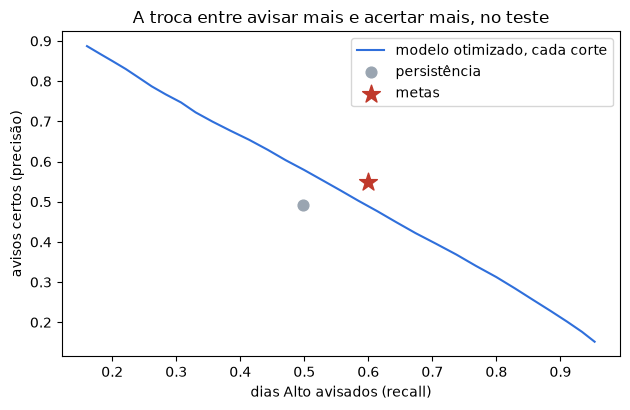

 corte  recall  precisao
   0.4   0.614    0.4764


In [8]:
curva = []
for corte in np.round(np.arange(0.10, 0.86, 0.025), 3):
    m = pm.metricas(y_te, pm.decidir(prob_te, corte, corte_medio))
    curva.append({'corte': corte, 'recall': m['recall_alto'], 'precisao': m['precisao_alto']})
curva = pd.DataFrame(curva)
curva.to_csv(RESULTADOS / 'troca_recall_precisao_teste.csv', index=False)

fig, eixo = plt.subplots(figsize=(6.4, 4.2))
eixo.plot(curva['recall'], curva['precisao'], color=AZUL, label='modelo otimizado, cada corte')
m_p = comparacao.loc['Persistência']
eixo.scatter([m_p['recall_alto']], [m_p['precisao_alto']], color=CINZA, s=60, zorder=3, label='persistência')
eixo.scatter([0.60], [0.55], color=VERMELHO, marker='*', s=180, zorder=3, label='metas')
eixo.set_xlabel('dias Alto avisados (recall)')
eixo.set_ylabel('avisos certos (precisão)')
eixo.set_title('A troca entre avisar mais e acertar mais, no teste')
eixo.legend()
plt.tight_layout()
plt.show()
perto = curva[(curva['recall'] >= 0.60)].sort_values('precisao', ascending=False).head(1)
print(perto.round(4).to_string(index=False))

In [9]:
mes_a_mes = []
for nome_parte, parte, y_parte, previsto in [('validação', validacao, y_va_np, prev_faixa_va), ('teste', teste, y_te_np, prev_faixa_te)]:
    for mes, indices in parte.groupby(parte['dia'].dt.to_period('M')).indices.items():
        m = pm.metricas(y_parte[indices], previsto[indices])
        r = pm.metricas(y_parte[indices], pm.persistencia(parte.iloc[indices]).values)
        mes_a_mes.append({'mês': str(mes), 'parte': nome_parte, '% dias Alto': round((y_parte[indices] == 'Alto').mean() * 100, 2),
                          'recall modelo': m['recall_alto'], 'precisão modelo': m['precisao_alto'], 'F1 Alto modelo': m['f1_alto'],
                          'F1 Alto persistência': r['f1_alto']})
mes_a_mes = pd.DataFrame(mes_a_mes).set_index('mês').round(4)
mes_a_mes.to_csv(RESULTADOS / 'mes_a_mes.csv')
mes_a_mes

,parte,% dias Alto,recall modelo,precisão modelo,F1 Alto modelo,F1 Alto persistência
mês,,,,,,
2024-10,validação,12.41,0.6561,0.5997,0.6266,0.6024
2024-11,teste,8.85,0.6028,0.6216,0.6121,0.5639
2024-12,teste,6.47,0.5092,0.5478,0.5278,0.4900
2025-01,teste,2.14,0.2971,0.3898,0.3372,0.3035
2025-02,teste,1.46,0.1667,0.4060,0.2363,0.2499


**Nenhum corte atinge as duas metas no período de teste.** A estrela fica fora da curva: para avisar 60 de cada 100
dias Alto, o corte precisa cair a 0,40, e a precisão vai a 47,6 de cada 100. As metas foram fixadas na Etapa 1, antes da
modelagem, e não foram mudadas depois.

**O resultado depende muito da época do ano.** O modelo final atinge as duas metas em **outubro e novembro**: em outubro, 65,6 dias Alto avisados e 60,0 avisos certos, de cada 100; em novembro, 60,3 dias Alto avisados e 62,2 avisos certos, de cada 100. A nota cai em
janeiro e fevereiro, com a chuva, quando há poucos dias Alto (cerca de 2%). Na prática, isso é o menos grave dos
cenários: o modelo é mais forte quando há mais fogo, e é aí que as equipes fazem falta. Outubro merece um
cuidado: ele foi usado para escolher os ajustes, então a nota dele é um pouco otimista.

## 4. Explicabilidade com o SHAP

O SHAP divide cada previsão entre as colunas: para um município-dia (um município num dia), diz quanto cada coluna empurrou o modelo a
favor ou contra o risco Alto. Somando os tamanhos desses empurrões em muitas previsões, sabemos quais colunas mais
pesam. A conta usa 5 000 município-dias sorteados do teste.

In [10]:
amostra_shap = teste.sample(5_000, random_state=SEMENTE)
explicador = shap.TreeExplainer(modelo)
indice_alto = list(modelo.classes_).index('Alto')
shap_alto = explicador.shap_values(amostra_shap[pm.FEATURES])[:, :, indice_alto]  # linhas × colunas × níveis

peso = pd.Series(np.abs(shap_alto).mean(axis=0), index=pm.FEATURES).sort_values(ascending=False)
peso_tabela = pd.DataFrame({'peso médio': peso.round(4), '% do peso total': (peso / peso.sum() * 100).round(1)})
peso_tabela.to_csv(RESULTADOS / 'peso_das_colunas_shap.csv')
peso_tabela.head(10)

,peso médio,% do peso total
focos_30d,0.4187,23.7
umidade_min_ontem,0.1586,9.0
chuva_7d,0.1574,8.9
area_km2,0.1508,8.5
focos_7d,0.1503,8.5
dias_com_foco_30d,0.1296,7.3
chuva_ontem,0.1084,6.1
sigla_uf,0.1025,5.8
focos_ontem,0.0945,5.3
dia_do_ano,0.0834,4.7


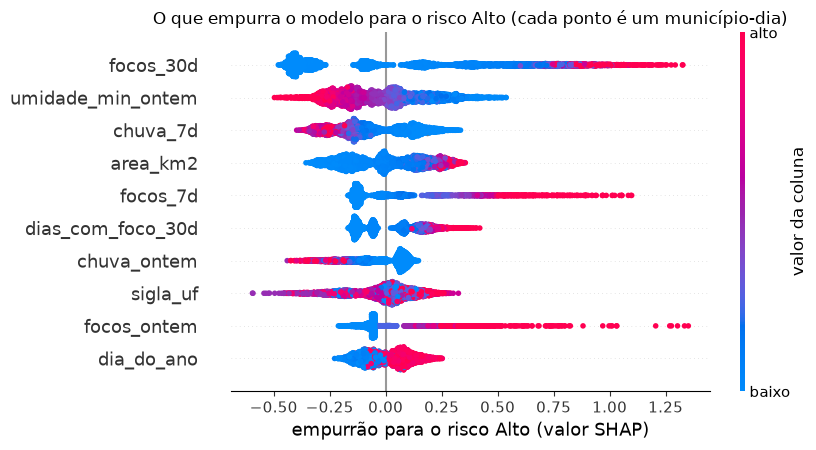

In [11]:
para_grafico = amostra_shap[pm.FEATURES].copy()
para_grafico['sigla_uf'] = para_grafico['sigla_uf'].cat.codes
shap.summary_plot(shap_alto, para_grafico, max_display=10, show=False, plot_size=(8.5, 4.6))
eixos_shap = plt.gcf().axes
eixos_shap[0].set_title('O que empurra o modelo para o risco Alto (cada ponto é um município-dia)')
eixos_shap[0].set_xlabel('empurrão para o risco Alto (valor SHAP)')
eixos_shap[-1].set_ylabel('valor da coluna')
eixos_shap[-1].set_yticklabels(['baixo', 'alto'])
plt.tight_layout()
plt.show()

**Como ler o gráfico:** cada ponto é um município-dia. À direita do zero, a coluna empurrou para o risco Alto; à esquerda,
contra. Vermelho é valor alto da coluna, e azul é valor baixo. Em `umidade_min_ontem`, os pontos vermelhos ficam à
esquerda: umidade alta afasta o risco. Em `focos_30d`, ficam à direita: muitos focos aproximam o risco.

**As 3 colunas que mais pesam no risco Alto:**

| Coluna | Peso | O que quer dizer |
|---|---|---|
| `focos_30d` | 23,7% | focos no município nos últimos 30 dias: lugar que vem queimando tende a seguir queimando |
| `umidade_min_ontem` | 9,0% | umidade mínima de ontem: quanto mais seco o ar, maior o risco |
| `chuva_7d` | 8,9% | chuva somada nos últimos 7 dias: quanto menos chuva, maior o risco |

O peso é a parte de cada coluna no total dos empurrões. A área do município e `focos_7d` vêm logo atrás (8,5% cada). Juntas,
as quatro colunas de histórico de focos somam 44,8% do peso, e as de clima da véspera mostradas na tabela (umidade,
chuva de 7 dias e chuva de ontem) somam 24,0%. Isso confirma as duas hipóteses da Etapa 1: o fogo de ontem avisa o de
hoje, e o ar seco acompanha o fogo. A área do município também pesa, como esperado, já que o alvo conta focos
sem dividir pela área.

**Um cuidado:** o SHAP mostra no que o modelo se apoia, e não o que causa o fogo. Ele não prova que o ar seco provoca
um incêndio; mostra que o modelo usa essa pista.

## 5. Testes de viés

Viés aqui quer dizer: o modelo trata pior algum grupo? A base não tem pessoas, então não há gênero nem idade. Os
grupos que importam são os lugares, porque é o lugar que deixa de receber equipe. Três recortes:

- **Região do país;**
- **Bioma** (grande tipo de vegetação): cada município recebe o bioma mais frequente nos seus focos. O bioma não
  entra no modelo, e aqui serve só para medir;
- **Distância até a estação meteorológica:** quanto mais longe a estação, menos o clima dela descreve o município.

Para cada grupo, a tabela mostra quantos dias Alto o modelo avisa (recall) e quantos avisos se confirmam (precisão),
comparados com a persistência no mesmo grupo. O número de dias Alto importa: um grupo com poucos dias Alto tem nota
instável. O teste cobre novembro a fevereiro, então grupos cuja seca cai em outra época têm pouco fogo nesse período.

In [12]:
bioma = pd.read_csv(RAIZ / 'dados' / 'processado' / 'bioma_municipio.csv')
grupos = teste[['regiao', 'id_municipio', 'distancia_estacao_km']].copy()
grupos['id_municipio'] = grupos['id_municipio'].astype('int64')
grupos = grupos.merge(bioma, on='id_municipio', how='left')
grupos['bioma'] = grupos['bioma'].fillna('sem foco registrado')
distancia_tipica = grupos.groupby('id_municipio')['distancia_estacao_km'].transform('median')
grupos['estacao'] = np.select([distancia_tipica > 150, distancia_tipica <= 50], ['mais de 150 km', 'até 50 km'], '50 a 150 km')

def por_grupo(coluna):
    linhas = []
    for nome, indices in grupos.groupby(coluna).indices.items():
        y_g = y_te_np[indices]
        m = pm.metricas(y_g, prev_faixa_te[indices])
        r = pm.metricas(y_g, persistencia_te[indices])
        linhas.append({coluna: nome, 'municípios': grupos['id_municipio'].iloc[indices].nunique(), 'dias Alto': int((y_g == 'Alto').sum()),
                       'recall modelo': m['recall_alto'], 'recall persistência': r['recall_alto'],
                       'precisão modelo': m['precisao_alto'], 'precisão persistência': r['precisao_alto'],
                       'F1 Alto modelo': m['f1_alto'], 'F1 Alto persistência': r['f1_alto']})
    tabela = pd.DataFrame(linhas).set_index(coluna).round(4).sort_values('dias Alto', ascending=False)
    tabela.to_csv(RESULTADOS / f'vies_por_{coluna}.csv')
    return tabela

vies_regiao = por_grupo('regiao')
vies_bioma = por_grupo('bioma')
vies_estacao = por_grupo('estacao')

# A mesma conta em outubro, quando ainda é seco em boa parte do país.
outubro = []
for nome, indices in validacao.groupby('regiao').indices.items():
    y_g = y_va_np[indices]
    m = pm.metricas(y_g, prev_faixa_va[indices])
    r = pm.metricas(y_g, pm.persistencia(validacao.iloc[indices]).values)
    outubro.append({'regiao': nome, 'dias Alto em outubro': int((y_g == 'Alto').sum()), 'recall modelo em outubro': m['recall_alto'],
                    'F1 Alto modelo em outubro': m['f1_alto'], 'F1 Alto persistência em outubro': r['f1_alto']})
outubro = pd.DataFrame(outubro).set_index('regiao').round(4)
outubro.to_csv(RESULTADOS / 'vies_por_regiao_outubro.csv')
vies_regiao

,municípios,dias Alto,recall modelo,recall persistência,precisão modelo,precisão persistência,F1 Alto modelo,F1 Alto persistência
regiao,,,,,,,,
Nordeste,1793,19418,0.4988,0.4838,0.5520,0.4801,0.5240,0.4819
Norte,444,7583,0.7279,0.6513,0.6274,0.6374,0.6740,0.6443
Centro-Oeste,467,1814,0.2690,0.3330,0.4561,0.3272,0.3384,0.3301
Sudeste,1666,1132,0.0618,0.1625,0.3030,0.1620,0.1027,0.1623
Sul,1191,636,0.1179,0.1808,0.2964,0.1737,0.1687,0.1772


In [13]:
outubro.loc[vies_regiao.index]

,dias Alto em outubro,recall modelo em outubro,F1 Alto modelo em outubro,F1 Alto persistência em outubro
regiao,,,,
Nordeste,9750,0.6103,0.6352,0.6014
Norte,6306,0.8219,0.7511,0.7309
Centro-Oeste,2234,0.6688,0.6087,0.5859
Sudeste,2761,0.4940,0.3981,0.3868
Sul,336,0.1250,0.1711,0.1568


In [14]:
vies_bioma[vies_bioma['dias Alto'] > 0]

,municípios,dias Alto,recall modelo,recall persistência,precisão modelo,precisão persistência,F1 Alto modelo,F1 Alto persistência
bioma,,,,,,,,
Caatinga,1093,10326,0.4175,0.4322,0.5097,0.4296,0.4590,0.4309
Amazônia,488,9891,0.7517,0.6742,0.6541,0.6601,0.6995,0.6671
Cerrado,1107,6986,0.5240,0.4911,0.5386,0.4851,0.5312,0.4881
Mata Atlântica,2685,3014,0.0863,0.1725,0.2938,0.1718,0.1334,0.1722
Pampa,128,198,0.1970,0.2424,0.2889,0.2412,0.2342,0.2418
Pantanal,7,168,0.7857,0.6250,0.5156,0.6140,0.6226,0.6195


In [15]:
vies_estacao

,municípios,dias Alto,recall modelo,recall persistência,precisão modelo,precisão persistência,F1 Alto modelo,F1 Alto persistência
estacao,,,,,,,,
50 a 150 km,1926,16024,0.5650,0.5309,0.5781,0.5240,0.5715,0.5274
até 50 km,3507,12348,0.4439,0.4421,0.5475,0.4380,0.4903,0.4400
mais de 150 km,128,2211,0.5893,0.5744,0.5859,0.5612,0.5876,0.5677


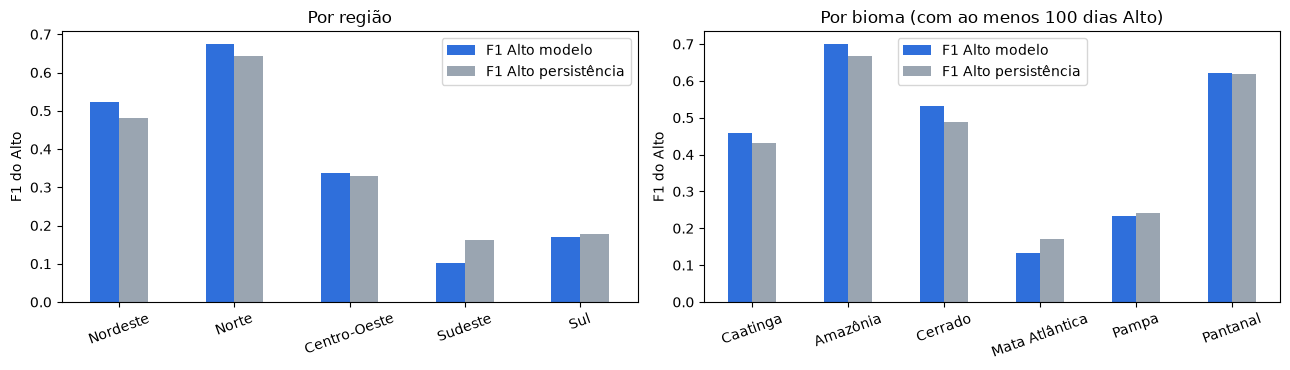

In [16]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
for eixo, tabela, titulo in [(eixos[0], vies_regiao, 'Por região'), (eixos[1], vies_bioma[vies_bioma['dias Alto'] >= 100], 'Por bioma (com ao menos 100 dias Alto)')]:
    tabela[['F1 Alto modelo', 'F1 Alto persistência']].plot(kind='bar', rot=20, color=[AZUL, CINZA], ax=eixo)
    eixo.set_title(titulo)
    eixo.set_xlabel('')
    eixo.set_ylabel('F1 do Alto')
plt.tight_layout()
plt.show()

**Há viés por região, e ele é grande.** No período de teste, o modelo avisa 73 de cada 100 dias Alto no Norte e 50 no
Nordeste, mas só 27 no Centro-Oeste, 12 no Sul e 6 no Sudeste. Em bioma, o retrato é o mesmo: 75 na Amazônia e 9 na
Mata Atlântica. No Sudeste, no Sul, na Mata Atlântica e no Pampa, o F1 do Alto do modelo fica abaixo do da persistência
(0,1027 contra 0,1623 no Sudeste e 0,1334 contra 0,1722 na Mata Atlântica). E Sudeste, Sul e Centro-Oeste têm recall abaixo do
da persistência.

**A causa provável é a época do ano e a falta de exemplos, e não uma falha de conta.** De novembro a fevereiro, é época de chuva em boa
parte dessas regiões: o Sudeste tem só 1 132 dias Alto no teste, contra 19 418 do Nordeste. Em outubro, ainda seco em boa parte do
país, o recall sobe de 6 para 49 no Sudeste e de 27 para 67 no Centro-Oeste. O Sul é diferente: fica baixo nos dois períodos
(12 no teste e 12 em outubro), com poucos dias Alto para aprender (336 em outubro). Mesmo com a causa explicada, o efeito é
real: um município do Sudeste com fogo fora de época recebe aviso muito menos vezes que um do Norte.

**O que fazer com isso:**
- no uso real, não trocar a prática local pelo modelo nas regiões Sudeste e Sul; nelas, o modelo entra só como apoio,
  e a régua "hoje = ontem" deve valer junto;
- acompanhar o recall por região todo mês, com um alerta se alguma região cair;
- no teste A/B (Etapa 2), usar os pares formados dentro de cada região para medir o efeito região por região;
- com mais anos de dados, treinar com mais de uma estação seca de cada região.

**Distância até a estação:** os 128 municípios cuja estação fica, em geral, a mais de 150 km não vão pior que os demais
(recall de 59 e F1 do Alto de 0,5876), e os três grupos superam a persistência. Eles são poucos e têm muito fogo, e o histórico
de focos diz muito sobre eles. Por isso, não há sinal de prejuízo para quem tem a estação longe, mas essa comparação não mede
o valor do clima.

## 6. Boletim em texto

O enunciado traz, como opcional, um texto automático gerado com ajuda de um modelo de linguagem (LLM). Este projeto
gera o boletim **com regra fixa**, sem LLM: uma frase padrão preenchida com o nível previsto e com os 3 fatores que
mais pesaram segundo o SHAP. A escolha é deliberada:
- todo número do texto vem direto da base, e nada é inventado;
- o repositório é público, e a regra fixa não precisa de chave de acesso a serviço pago;
- qualquer pessoa reproduz o resultado exato, sem internet.

O boletim não mostra porcentagem, de propósito: como o modelo dá peso maior aos níveis raros, a "probabilidade" dele
serve para ordenar os dias, e não é uma chance real de fogo.

O exemplo usa o dia do teste com mais avisos Alto. Cada linha mostra, entre colchetes, o que de fato aconteceu: o boletim erra às vezes, como o modelo.

In [17]:
NOMES_LEGIVEIS = {
    'focos_ontem': ('focos ontem', '{:.0f}'), 'focos_7d': ('focos nos últimos 7 dias', '{:.0f}'),
    'focos_30d': ('focos nos últimos 30 dias', '{:.0f}'), 'dias_com_foco_30d': ('dias com foco nos últimos 30', '{:.0f}'),
    'umidade_min_ontem': ('umidade mínima de ontem', '{:.0f}%'), 'temp_max_ontem': ('temperatura máxima de ontem', '{:.0f} °C'),
    'chuva_ontem': ('chuva de ontem', '{:.1f} mm'), 'chuva_7d': ('chuva nos últimos 7 dias', '{:.1f} mm'),
    'vento_ontem': ('vento de ontem', '{:.1f} m/s'), 'distancia_estacao_km': ('distância até a estação', '{:.0f} km'),
    'mes': ('mês do ano', '{:.0f}'), 'dia_do_ano': ('época do ano', 'dia {:.0f}'), 'area_km2': ('área do município', '{:.0f} km²'),
    'pct_floresta': ('floresta no município', '{:.0f}%'), 'pct_natural_nao_florestal': ('vegetação natural não florestal', '{:.0f}%'),
    'pct_pastagem': ('pastagem no município', '{:.0f}%'), 'pct_agricultura': ('agricultura no município', '{:.0f}%'),
    'pct_mosaico': ('mosaico de usos no município', '{:.0f}%'), 'pct_nao_vegetada': ('área não vegetada', '{:.0f}%'),
    'pct_agua': ('água no município', '{:.0f}%'), 'perda_nativa_5a': ('perda de vegetação nativa em 5 anos', '{:.1f}% da área'),
    'sigla_uf': ('estado', '{}'),
}
ORIENTACAO = {'Alto': 'Manter equipe de prontidão.', 'Médio': 'Manter atenção e equipe de sobreaviso.', 'Baixo': 'Sem necessidade de prontidão.'}
nomes_municipios = pd.read_csv(RAIZ / 'dados' / 'externos' / 'municipios.csv').set_index('codigo_ibge')['nome']

def valor_legivel(coluna, valor):
    if pd.isna(valor):
        return 'sem dado'
    if coluna.startswith('pct_') or coluna == 'perda_nativa_5a':  # na base, essas colunas são proporções de 0 a 1
        valor = valor * 100
    return NOMES_LEGIVEIS[coluna][1].format(valor).replace('.', ',')

def boletim(linha, shap_da_linha, nivel):
    # Os 3 fatores que mais empurraram para o nível previsto.
    fatores = pd.Series(shap_da_linha, index=pm.FEATURES).sort_values(ascending=False).head(3).index
    texto = '; '.join(f'{NOMES_LEGIVEIS[c][0]}: {valor_legivel(c, linha[c])}' for c in fatores)
    nome = nomes_municipios.get(int(linha['id_municipio']), 'Município')
    return f"{nome} ({linha['sigla_uf']}), {linha['dia']:%d/%m/%Y}: risco {nivel.upper()}. O que mais pesou: {texto}. {ORIENTACAO[nivel]}"

teste_prev = teste.assign(previsto=prev_faixa_te)
dia_exemplo = teste_prev[teste_prev['previsto'] == 'Alto']['dia'].value_counts().idxmax()
do_dia = teste_prev[teste_prev['dia'] == dia_exemplo]
exemplos = pd.concat([do_dia[do_dia['previsto'] == nivel].sort_values('focos_7d', ascending=False).head(2) for nivel in ['Alto', 'Médio', 'Baixo']])
valores_ex = explicador.shap_values(exemplos[pm.FEATURES])
classes = list(modelo.classes_)
textos = [boletim(linha, valores_ex[i, :, classes.index(linha['previsto'])], linha['previsto'])
          for i, (_, linha) in enumerate(exemplos.iterrows())]
pd.DataFrame({'id_municipio': exemplos['id_municipio'].values, 'dia': exemplos['dia'].dt.date.values, 'real': exemplos['nivel_risco'].astype(str).values,
              'previsto': exemplos['previsto'].values, 'boletim': textos}).to_csv(RESULTADOS / 'boletim_exemplo.csv', index=False)
print(f'Dia do exemplo: {dia_exemplo:%d/%m/%Y}\n')
for texto, real in zip(textos, exemplos['nivel_risco'].astype(str)):
    print(texto, f'[real: {real}]\n')

Dia do exemplo: 02/11/2024

Portel (PA), 02/11/2024: risco ALTO. O que mais pesou: focos ontem: 1073; focos nos últimos 30 dias: 16163; focos nos últimos 7 dias: 5752. Manter equipe de prontidão. [real: Alto]

Moju (PA), 02/11/2024: risco ALTO. O que mais pesou: focos ontem: 1432; focos nos últimos 30 dias: 10041; focos nos últimos 7 dias: 4426. Manter equipe de prontidão. [real: Alto]

Itapetinga (BA), 02/11/2024: risco MÉDIO. O que mais pesou: dias com foco nos últimos 30: 16; área do município: 1651 km²; época do ano: dia 307. Manter atenção e equipe de sobreaviso. [real: Baixo]

Riacho Frio (PI), 02/11/2024: risco MÉDIO. O que mais pesou: dias com foco nos últimos 30: 18; área do município: 2221 km²; época do ano: dia 307. Manter atenção e equipe de sobreaviso. [real: Médio]

Júlio Borges (PI), 02/11/2024: risco BAIXO. O que mais pesou: focos ontem: 0; estado: PI; agricultura no município: 0%. Sem necessidade de prontidão. [real: Médio]

Conceição do Araguaia (PA), 02/11/2024: risc

## 7. Conclusão do projeto: a hipótese se confirma?

**Hipótese:** com o que se sabe até a véspera, um modelo avisa os dias de risco Alto melhor do que a regra "hoje = ontem"
e reduz o custo de posicionar equipes.

**Resposta: confirmada em parte.** O modelo final é melhor que a régua e custa menos, mas não atinge a meta de dias Alto
avisados, que é a mais importante para quem precisa chegar a tempo.

| Meta | Persistência | Modelo final | Atingida? |
|---|---|---|---|
| Acerto geral (F1 macro) de pelo menos 0,55 | 0,5490 | 0,5677 | **sim** |
| Pelo menos 55 de cada 100 avisos Alto certos | 49,2 | 56,8 | **sim** |
| Pelo menos 60 de cada 100 dias Alto avisados | 49,8 | 51,8 | **não** (faltam 8,2 pontos) |
| Custo menor que o da persistência | R$ 434,8 milhões | R$ 415,8 milhões | **sim**, R$ 19,0 milhões a menos |

**O que isso significa para quem decide:**
1. **Vale usar o modelo como lista diária de prioridade,** principalmente nos meses de mais fogo e no Norte e no
   Nordeste, onde ele é mais forte. Ele avisa um pouco mais de dias Alto e erra menos avisos que a régua mínima, e supera a
   persistência nas 3 faixas maiores de município. O teste em municípios nunca vistos, da Etapa 2, foi feito com a regressão
   logística, antes da otimização, e mostrou que ela não depende de "conhecer" o lugar.
2. **Ele não substitui a prática das equipes.** A comparação foi com uma referência estatística mínima. A régua
   ideal, a previsão de risco do Instituto Nacional de Pesquisas Espaciais (INPE), não pôde ser medida, porque na base
   ela só existe quando já há fogo.
3. **O gestor escolhe o corte.** Mais avisos custam mais prontidão, e menos avisos deixam mais fogo sem equipe. A
   seção 7.2 da Etapa 2 mostra o preço de cada opção.
4. **Sudeste e Sul exigem cuidado,** pelo viés da seção 5.
5. **A economia em reais é uma estimativa.** Depende da premissa dos 5 hectares, e só o teste A/B planejado na Etapa 2
   pode comprovar o ganho.

**Principais limitações:** um só ano de dados, com uma única estação seca no treino e nenhum dia de outubro a dezembro;
uso do solo de 2021; clima vindo
da estação mais próxima; o alvo mede o fogo visto por satélite e conta focos sem dividir pela área.

**Próximos passos:** treinar com mais anos, testar o risco em focos por km² e rodar o teste A/B numa estação seca.